<div align="center">
  <img src="https://capsule-render.vercel.app/api?type=waving&color=0:0f2027,50:203a43,100:2c5364&height=200&section=header&text=Deep%Learning%20Projet&fontSize=50&fontColor=ffffff&animation=fadeIn&fontAlignY=38&desc=Fall%20Semester%202026/2027&descAlignY=58&descSize=18" width="100%" alt="banner"/>
</div>

<h2 align="center">Team</h2>

<table align="center">
  <tr>
    <td align="center">
      <a href="https://github.com/USER0">
        <img src="https://github.com/USER0.png" width="100" style="border-radius:50%" alt="Nome 0"/><br/>
        <b>Carlota Marto 20241729</b>
      </a>
    </td>
    <td align="center">
      <a href="https://github.com/DiogoCapelaGoncalves">
        <img src="https://github.com/DiogoCapelaGoncalves.png" width="100" style="border-radius:50%" alt="Nome 1"/><br/>
        <b>Diogo Capela 20241817</b>
      </a>
    </td>
    <td align="center">
      <a href="https://github.com/USER2">
        <img src="https://github.com/USER2.png" width="100" style="border-radius:50%" alt="Nome 2"/><br/>
        <b>Henrique Santos 20241752</b>
    <td align="center">
      <a href="https://github.com/USER4">
        <img src="https://github.com/USER4.png" width="100" style="border-radius:50%" alt="Nome 4"/><br/>
        <b>Laura Lisboa 20241783</b>
      </a>
    </td>
    <td align="center">
      <a href="https://github.com/tiago2806">
        <img src="https://github.com/tiago2806.png" width="100" style="border-radius:50%" alt="Nome 5"/><br/>
        <b>Homo Maximus 20241728</b>
      </a>
    </td>
  </tr>
</table>

<table align="center">
  <tr>
    <th>Índice</th>
  </tr>
  <tr>
    <td><a href="#sobre">1. Sobre</a></td>
  </tr>
  <tr>
    <td><a href="#instalação">2. Instalação</a></td>
  </tr>
  <tr>
    <td><a href="#utilização">3. Utilização</a></td>
  </tr>
  <tr>
    <td><a href="#resultados">4. Resultados</a></td>
  </tr>
  <tr>
    <td><a href="#equipa">5. Equipa</a></td>
  </tr>
</table>

<h1 style="color:#2c5364; border-bottom:2px solid #2c5364; padding-bottom:4px;">Imports</h1>

In [ ]:
import pandas as pd
import tensorflow as tf
import os
import matplotlib.pyplot as plt
import numpy as np
import random
import hashlib

from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import LabelEncoder

from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input as vgg_preprocess

<h1 style="color:#2c5364; border-bottom:2px solid #2c5364; padding-bottom:4px;">Lables Dataset Exploration</h1>

In [46]:
labels = pd.read_csv("../Data/Tiny_ImageNet_Project_2026_Students/labels.csv")

In [47]:
labels.head()

,filename,class_id,description
0,image_000001.JPEG,n03042490,cliff dwelling
1,image_000002.JPEG,n02793495,barn
2,image_000003.JPEG,n02793495,barn
3,image_000004.JPEG,n02793495,barn
4,image_000005.JPEG,n02793495,barn


<div style="border-left:4px solid #2c5364; background:#2c536422; padding:8px 14px; border-radius:4px;">
<b>Note:</b> In here we can see a glimpse of the labels dataset, which contains the JPEG file name, class id which is the unique identifier of the photo description and finally the description of the photo
</div>

In [48]:
labels.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 60000 entries, 0 to 59999
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   filename     60000 non-null  object
 1   class_id     60000 non-null  object
 2   description  60000 non-null  object
dtypes: object(3)
memory usage: 1.4+ MB


<div style="border-left:4px solid #2c5364; background:#2c536422; padding:8px 14px; border-radius:4px;">
<b>Note:</b> We can see that we don't have any missing value in each of the columns, all of them correspond to 60 000 items
</div>

In [49]:
labels.describe()

,filename,class_id,description
count,60000,60000,60000
unique,60000,200,200
top,image_000001.JPEG,n03854065,"organ, pipe organ"
freq,1,549,549


<div style="border-left:4px solid #2c5364; background:#2c536422; padding:8px 14px; border-radius:4px;">
<b>Note:</b> The photos correspont to 60 000 different file names each with 1 of frequency do prove that, the class id and description both correspond to 200 different classes with a max of 549 repetitions
</div>

In [ ]:
file_names_numbers = labels["filename"].str.extract(r'(\d+)', expand=False).astype(int)

expected = np.arange(1, len(file_names_numbers) + 1)
flag = np.array_equal(file_names_numbers.values, expected)

print(flag)

True


<div style="border-left:4px solid #2c5364; background:#2c536422; padding:8px 14px; border-radius:4px;">
<b>Note:</b> This is needed to check if the file names go from 1 to 60 000 in order and without missing any element
</div>

In [51]:
labels[["class_id", "description"]].drop_duplicates()

,class_id,description
0,n03042490,cliff dwelling
1,n02793495,barn
29,n03706229,magnetic compass
32,n03584254,iPod
53,n04560804,water jug
...,...,...
7810,n04070727,"refrigerator, icebox"
7994,n04179913,sewing machine
8025,n07711569,mashed potato
10157,n02123394,Persian cat


<div style="border-left:4px solid #2c5364; background:#2c536422; padding:8px 14px; border-radius:4px;">
<b>Note:</b> This proves that we contain exactly 200 classes each corresponding to each class id
</div>

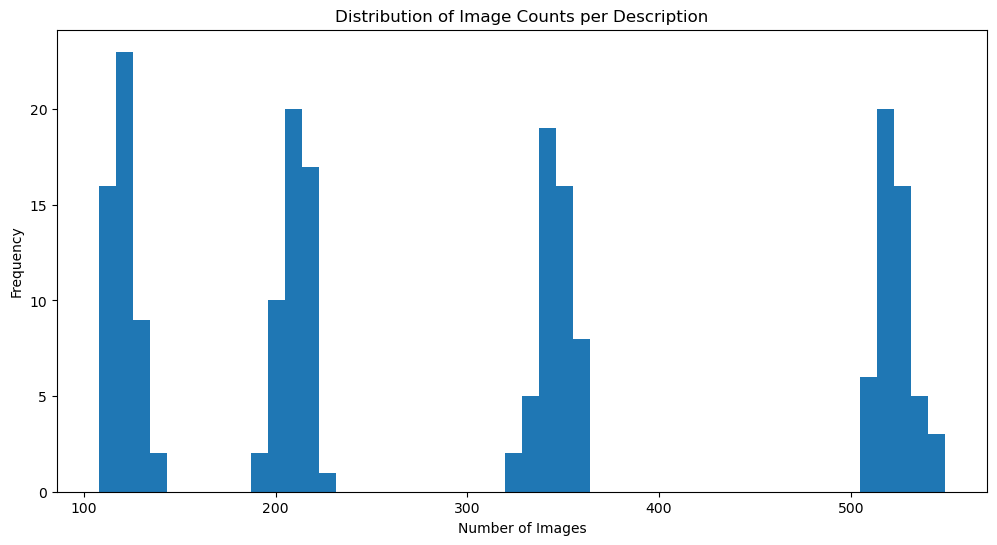

In [52]:
counts = labels["description"].value_counts()

plt.figure(figsize=(12, 6))
plt.hist(counts.values, bins=50)
plt.xlabel("Number of Images")
plt.ylabel("Frequency")
plt.title("Distribution of Image Counts per Description")
plt.show()

<div style="border-left:4px solid #2c5364; background:#2c536422; padding:8px 14px; border-radius:4px;">
<b>Note:</b> In here we can conclude that we have classes imbalance with very different frequencies distributed around 4 clusters, one around 120, other 200, another 350 and another with 520 of frequency
</div>

In [53]:
max_image_count =counts.max()
max_image_count

549

<div style="border-left:4px solid #2c5364; background:#2c536422; padding:8px 14px; border-radius:4px;">
<b>Note:</b> Max frequency is 549
</div>

In [54]:
min_image_count = counts.min()
min_image_count

108

<div style="border-left:4px solid #2c5364; background:#2c536422; padding:8px 14px; border-radius:4px;">
<b>Note:</b> Minimum frequency is 108
</div>

In [55]:
ratio_image_count = max_image_count / min_image_count
ratio_image_count

5.083333333333333

<div style="border-left:4px solid #2c5364; background:#2c536422; padding:8px 14px; border-radius:4px;">
<b>Note:</b> The largest class has ~5.1× more images than the smallest (549 vs 108). During training, the model therefore sees some classes about 5 times more often than others, so it may learn their patterns better.
</div>

In [56]:
mean = counts.mean()
mean

np.float64(300.0)

<div style="border-left:4px solid #2c5364; background:#2c536422; padding:8px 14px; border-radius:4px;">
<b>Note:</b> The average frequency is 300
</div>

In [57]:
cluster_1 = (counts < 150).sum()
cluster_2 = ((counts >= 150) & (counts < 300)).sum()
cluster_3 = ((counts >= 300) & (counts < 500)).sum()
cluster_4 = (counts >= 500).sum()

print(f"Cluster 1 (less than 150 images): {cluster_1} classes")
print(f"Cluster 2 (150 to 299 images): {cluster_2} classes")
print(f"Cluster 3 (300 to 499 images): {cluster_3} classes")
print(f"Cluster 4 (500 or more images): {cluster_4} classes")


Cluster 1 (less than 150 images): 50 classes
Cluster 2 (150 to 299 images): 50 classes
Cluster 3 (300 to 499 images): 50 classes
Cluster 4 (500 or more images): 50 classes


<div style="border-left:4px solid #2c5364; background:#2c536422; padding:8px 14px; border-radius:4px;">
<b>Note:</b> As seen before we have class imbalance in which each cluster has 50 classes
</div>

<h1 style="color:#2c5364; border-bottom:2px solid #2c5364; padding-bottom:4px;">Images exploration</h1>

In [58]:
path = '../Data/Tiny_ImageNet_Project_2026_Students/images'

In [ ]:
file_names = labels["filename"].tolist()

In [ ]:
images_paths = [os.path.join(path, f"{file_name}") for file_name in file_names] # Needed to get the full path to the images

In [ ]:
def see_image(image_path):
    image = tf.io.read_file(image_path)
    image = tf.io.decode_jpeg(image, channels=3) # Channels = 3 forces the image into a image in RGB
    plt.figure(figsize=(4,4))
    plt.imshow(image)
    plt.axis("off")
    plt.show()

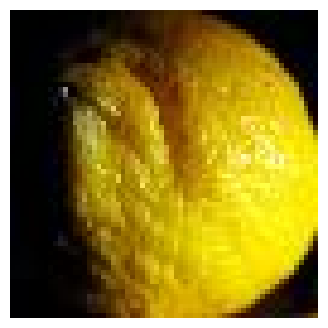

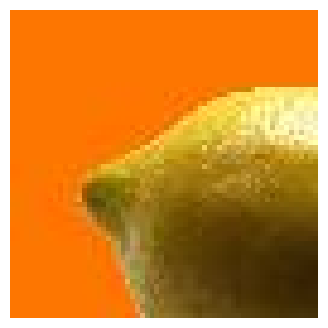

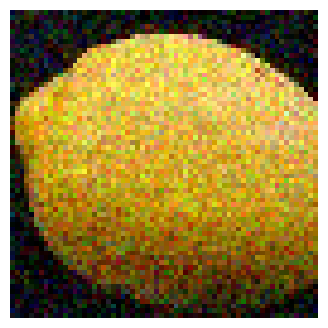

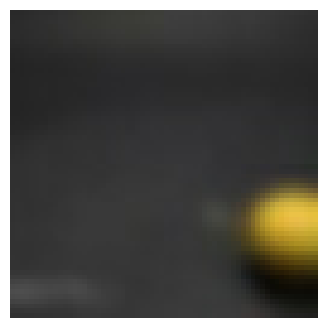

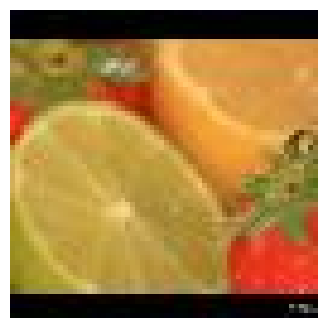

In [62]:
for i in range(1000, 1005):
    see_image(images_paths[i])

<h3 style="color:#2c5364; padding-bottom:3px;">Confirm if we can see every image and it's shape</h3>

In [ ]:
def get_image(image_path):
    image = tf.io.read_file(image_path)
    image = tf.io.decode_jpeg(image, channels=3)
    image = image / 255
    return image

In [64]:
flag = True
for i in range(len(images_paths)):
    try:
        image = get_image(images_paths[i])
        if image.shape != (64, 64, 3):
            flag = False
            break
    except Exception as e:
        print(f"Error loading image {images_paths[i]}: {e}")
        flag = False
        break
print(flag)

True


<div style="border-left:4px solid #2c5364; background:#2c536422; padding:8px 14px; border-radius:4px;">
<b>Note:</b> With this we know every picture has a shape of (64,64) pixels and that is JPEG
</div>

In [65]:
def get_how_many_channels(image_path):
    raw = tf.io.read_file(image_path)
    image = tf.io.decode_jpeg(raw, channels=0)
    return image.shape[-1]

In [66]:
flag = True
count = 0 
channel_not_3 = []
for i in range(len(images_paths)):
    try:
        channel = get_how_many_channels(images_paths[i])
        if channel != 3:
            flag = False
            count += 1
            channel_not_3.append(images_paths[i])
    except Exception as e:
        print(f"Error loading image {images_paths[i]}: {e}")
        flag = False
        break
print(f"Count : {count}")
print(flag)

Count : 806
False


<div style="border-left:4px solid #2c5364; background:#2c536422; padding:8px 14px; border-radius:4px;">
<b>Note:</b> Now we know that our data ins't just RGB photos, we have also 806 that are just black and white with a channel equal to 1 and the rest being RGB photos with channel equal to 3
</div>

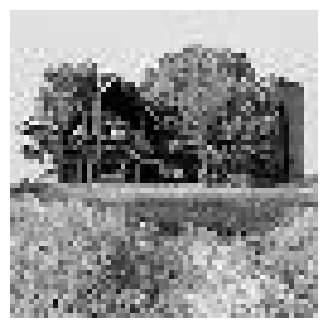

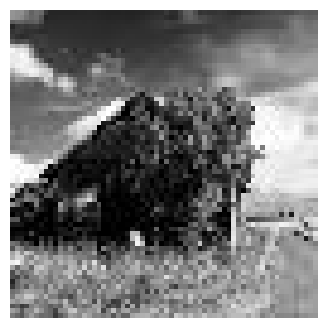

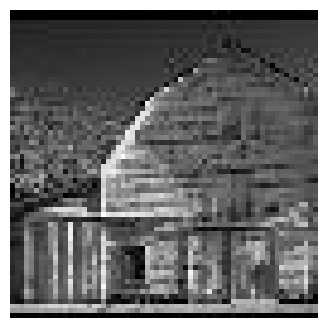

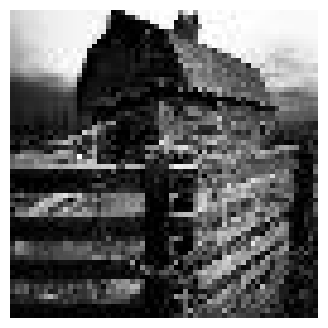

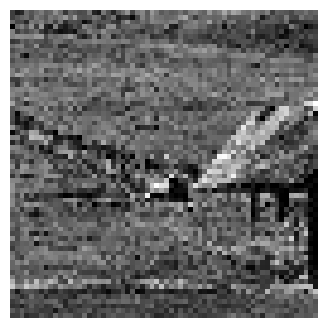

In [67]:
for i in range(5):
    see_image(channel_not_3[i])

<h3 style="color:#2c5364; padding-bottom:3px;">Check duplicate images</h3>

In [ ]:
def turn_into_hash_string(image_path):
    raw = tf.io.read_file(image_path) # Get the raw bytes of the image in the file
    image = tf.io.decode_jpeg(raw, channels=3) # Decode the raw bytes into a tensor 
    numpy_array_image = image.numpy() # Convert the tensor into a numpy array
    bytes_image = numpy_array_image.tobytes() # Convert the numpy array into bytes
    mixer_image = hashlib.md5(bytes_image) # Create a hash object, like a class object, using the MD5 algorithm and update it with the bytes of the image
    image_into_text = mixer_image.hexdigest() # Get the hexadecimal representation of the hash, which is just a string of characters that uniquely identifies the image
    return image_into_text

labels["hash"] = [turn_into_hash_string(p) for p in images_paths] # fingerprint of every image (about a minute) 

In [69]:
labels["is_duplicate"] = labels["hash"].duplicated(keep=False)           # True for EVERY copy of a repeated fingerprint
labels["n_labels"] = labels.groupby("hash")["class_id"].transform("nunique")  # different labels per fingerprint group (>1 = conflict)

print("Images involved in duplicates:", labels["is_duplicate"].sum())          # how many images have an identical twin
print("Images with conflicting labels:", (labels["n_labels"] > 1).sum())       # same picture, different labels

conflicts = labels[labels["n_labels"] > 1].sort_values("hash")                 # conflicting ones, twins side by side
conflicts                                                         

Images involved in duplicates: 12
Images with conflicting labels: 12


,filename,class_id,description,hash,is_duplicate,n_labels
27766,image_027767.JPEG,n03404251,fur coat,0f400b529da4df75a409602c4c5e7db8,True,2
47291,image_047292.JPEG,n02988304,CD player,0f400b529da4df75a409602c4c5e7db8,True,2
593,image_000594.JPEG,n03891332,parking meter,37bfb8e5b32c68152bfc8d2c7a53ee0b,True,2
13623,image_013624.JPEG,n07747607,orange,37bfb8e5b32c68152bfc8d2c7a53ee0b,True,2
11907,image_011908.JPEG,n01950731,"sea slug, nudibranch",3a7055e30d47b66c38cf3872564d9ddc,True,2
30312,image_030313.JPEG,n01945685,slug,3a7055e30d47b66c38cf3872564d9ddc,True,2
15109,image_015110.JPEG,n03584254,iPod,55985fcb729f347a8edf056fa147fb07,True,2
48341,image_048342.JPEG,n04254777,sock,55985fcb729f347a8edf056fa147fb07,True,2
1090,image_001091.JPEG,n07749582,lemon,59f2a108dfe8ec55424f514f2ff96a1c,True,2
59133,image_059134.JPEG,n07753592,banana,59f2a108dfe8ec55424f514f2ff96a1c,True,2


<div style="border-left:4px solid #2c5364; background:#2c536422; padding:8px 14px; border-radius:4px;">
<b>Note:</b> With hash library we can transform the pixels image into a string and compare if they are equal confirming the existence of 12 duplicate photos with 2 or more different labels
</div>

Image with index 27766 label is fur coat, the image is the following:


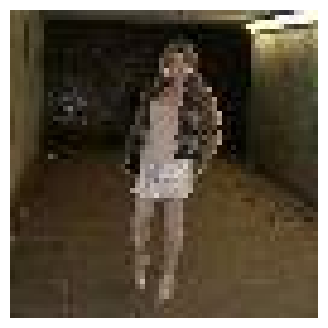

Image with index 47291 label is CD player, the image is the following:


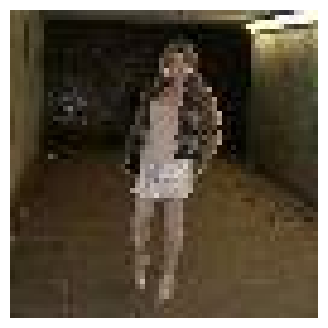

Image with index 593 label is parking meter, the image is the following:


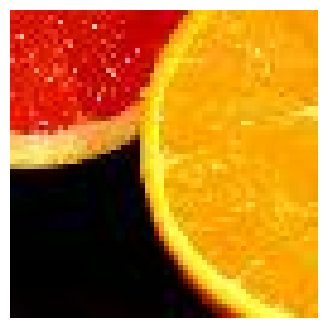

Image with index 13623 label is orange, the image is the following:


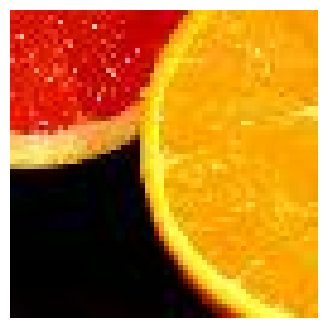

Image with index 11907 label is sea slug, nudibranch, the image is the following:


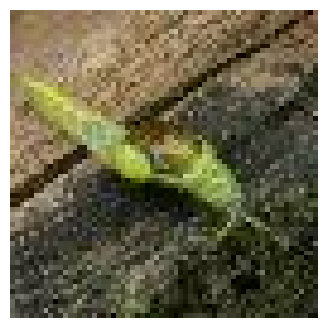

Image with index 30312 label is slug, the image is the following:


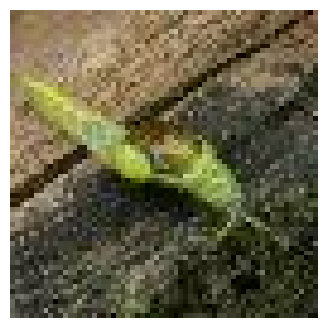

Image with index 15109 label is iPod, the image is the following:


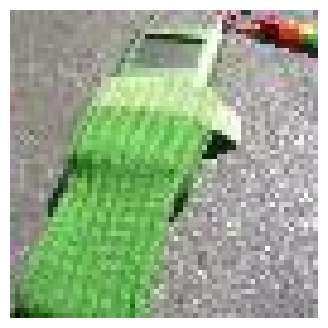

Image with index 48341 label is sock, the image is the following:


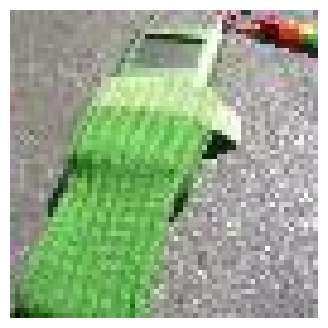

Image with index 1090 label is lemon, the image is the following:


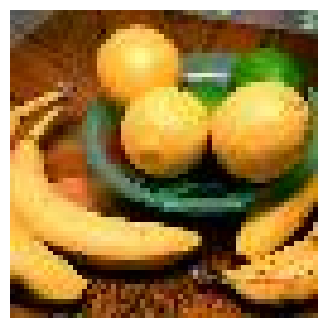

Image with index 59133 label is banana, the image is the following:


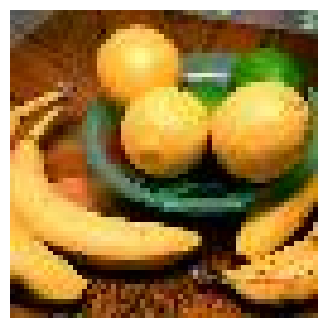

Image with index 33613 label is spiny lobster, langouste, rock lobster, crawfish, crayfish, sea crawfish, the image is the following:


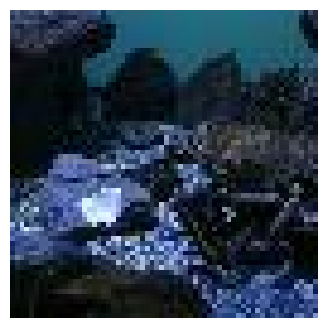

Image with index 40382 label is American lobster, Northern lobster, Maine lobster, Homarus americanus, the image is the following:


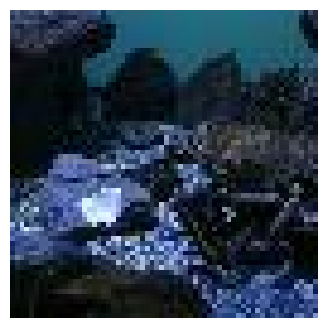

In [70]:
for i in conflicts.index:                                        # i = the row labels (e.g. 1503, 8821, ...)
    print(f"Image with index {i} label is {conflicts.loc[i, "description"]}, the image is the following:")
    see_image(os.path.join(path, conflicts.loc[i, "filename"])) # look up that row's filename

<div style="border-left:4px solid #2c5364; background:#2c536422; padding:8px 14px; border-radius:4px;">
<b>Note:</b> The first 2 images are defensible the rest is very subjective
</div>

<h3 style="color:#2c5364; padding-bottom:3px;">Check near duplicate images</h3>

<div style="border-left:4px solid #2c5364; background:#2c536422; padding:8px 14px; border-radius:4px;">
<b>Method:</b> two images are near-duplicates if their ResNet50 embeddings have a cosine similarity above a threshold. Pairs already found by the MD5 hash (exact copies) are excluded.
</div>

In [ ]:
IMG_SIZE, BATCH = 224, 128

def load_for_backbone(image_path):
    image = tf.io.decode_jpeg(tf.io.read_file(image_path), channels=3)  # channels=3 also fixes the 806 grayscale images
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))
    return preprocess_input(image)

ds = (tf.data.Dataset.from_tensor_slices(images_paths)
      .map(load_for_backbone, num_parallel_calls=tf.data.AUTOTUNE)
      .batch(BATCH).prefetch(tf.data.AUTOTUNE))

In [72]:
backbone = ResNet50(weights="imagenet", include_top=False, pooling="avg",
                    input_shape=(IMG_SIZE, IMG_SIZE, 3))
embeddings = backbone.predict(ds, verbose=1)
# np.save("embeddings_resnet50.npy", embeddings)   # so you never have to recompute

469/469 ━━━━━━━━━━━━━━━━━━━━ 716s 2s/step


In [73]:
X = embeddings / np.linalg.norm(embeddings, axis=1, keepdims=True)   # L2-normalise

In [ ]:
thresholds = [0.85, 0.90, 0.93, 0.95, 0.98]
raw = {t: 0 for t in thresholds}

for start in range(0, len(X), 1000):
    sims = X[start:start+1000] @ X.T
    for r in range(sims.shape[0]):
        sims[r, start + r] = -1
    for t in thresholds:
        raw[t] += (sims > t).sum()

counts_per_threshold = {t: raw[t] // 2 for t in thresholds}

print(counts_per_threshold)

{0.85: np.int64(23578), 0.9: np.int64(1017), 0.93: np.int64(75), 0.95: np.int64(9), 0.98: np.int64(6)}


   <div style="border-left:4px solid #2c5364; background:#2c536422; padding:8px 14px; border-radius:4px;">
   <b>Note:</b> The counts include the 6 exact (MD5) duplicate pairs found earlier, since exact copies have a similarity of about 1.0. That is why 0.98 gives 6 (exact copies only) and 0.95 gives 9 (6 exact pairs plus 3 near-duplicate pairs). Subtracting the 6 exact pairs gives the near-duplicates only: 3 at 0.95 and 0 at 0.98. The counts are summed over all batches and divided by 2 once at the end, so pairs split across two batches are not lost.
   </div>

In [120]:
THRESH = 0.95 #Under 0.95 thershold the images are different

pairs = []
for start in range(0, len(X), 1000):
    sims = X[start:start+1000] @ X.T                 # similarity of 1000 images vs all images
    for r in range(sims.shape[0]):
        sims[r, start + r] = -1                      # ignore comparing an image with itself
    rows, cols = np.where(sims > THRESH)
    for r, c in zip(rows, cols):
        if start + r < c:                            # keep each pair only once
            pairs.append((start + r, c, sims[r, c]))

pairs = pd.DataFrame(pairs, columns=["i", "j", "sim"])
pairs["same_label"] = labels["class_id"].values[pairs["i"]] == labels["class_id"].values[pairs["j"]]
pairs["exact"] = labels["hash"].values[pairs["i"]] == labels["hash"].values[pairs["j"]]   # already found by the MD5 hash

near = pairs[~pairs["exact"]].sort_values("sim", ascending=False)
print(len(near), "near-duplicate pairs")
print(near["same_label"].value_counts())

3 near-duplicate pairs
same_label
False    3
Name: count, dtype: int64


<div style="border-left:4px solid #2c5364; background:#2c536422; padding:8px 14px; border-radius:4px;">
<b>Note:</b> We can see that we have 3 possible pairs of near duplicate images
</div>

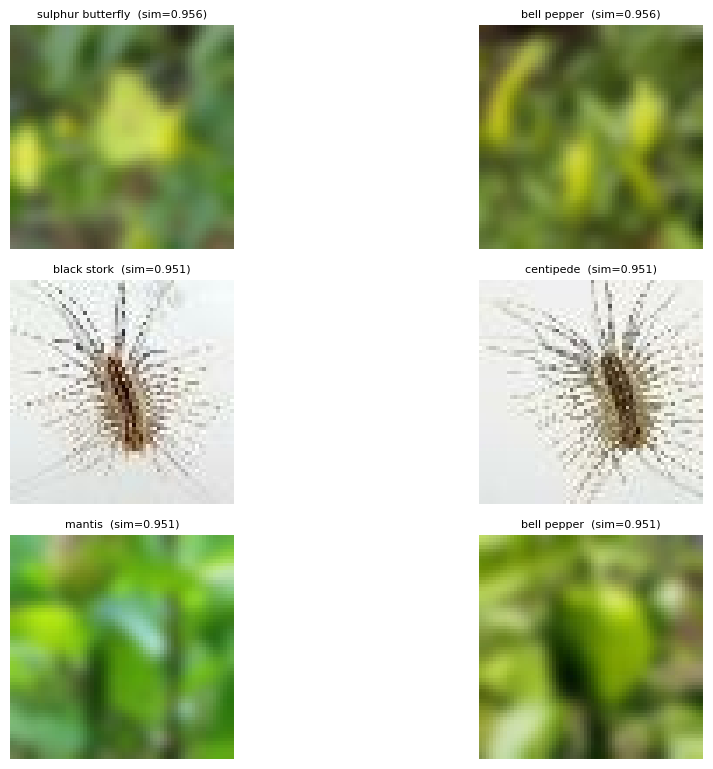

In [121]:
sample = near.head(10)   # try near.tail(10) as well

plt.figure(figsize=(12, 2.6 * len(sample)))
for k, (_, p) in enumerate(sample.iterrows()):
    for side, idx in enumerate([int(p["i"]), int(p["j"])]):
        plt.subplot(len(sample), 2, 2 * k + side + 1)
        plt.imshow(get_image(os.path.join(path, labels.loc[idx, "filename"])))
        plt.title(f"{labels.loc[idx, 'description'].split(',')[0]}  (sim={p['sim']:.3f})", fontsize=8)
        plt.axis("off")
plt.tight_layout()
plt.show()

<div style="border-left:4px solid #2c5364; background:#2c536422; padding:8px 14px; border-radius:4px;">
<b>Note:</b> The first and last we could say that they are not the same image but similar, the second is clearly a mislabeled image. So we can conclude that we don't have images that are repeated
</div>

In [77]:
near_table = near.copy()
near_table["desc_i"] = labels.loc[near_table["i"], "description"].str.split(",").str[0].values
near_table["desc_j"] = labels.loc[near_table["j"], "description"].str.split(",").str[0].values
near_table

,i,j,sim,same_label,exact,desc_i,desc_j
2,9138,44175,0.955591,False,False,sulphur butterfly,bell pepper
6,23127,23561,0.951295,False,False,black stork,centipede
4,12270,44211,0.950594,False,False,mantis,bell pepper


In [78]:
row = near_table[(near_table["desc_i"] == "black stork") | (near_table["desc_j"] == "black stork")].iloc[0]
idx_of_black_stork = int(row["i"]) if row["desc_i"] == "black stork" else int(row["j"])
print(idx_of_black_stork)

23127


   <div style="border-left:4px solid #2c5364; background:#2c536422; padding:8px 14px; border-radius:4px;">
   <b>Note:</b> at 0.95 only 3 near-duplicate pairs were found. One is a true near-duplicate with a label error (centipede labelled as black stork); the other two are false positives caused by blurry images with similar colours. Near-duplicates are not a major problem in this dataset.
   </div>

<h3 style="color:#2c5364; padding-bottom:3px;">Randomly check the images descriptions</h3>

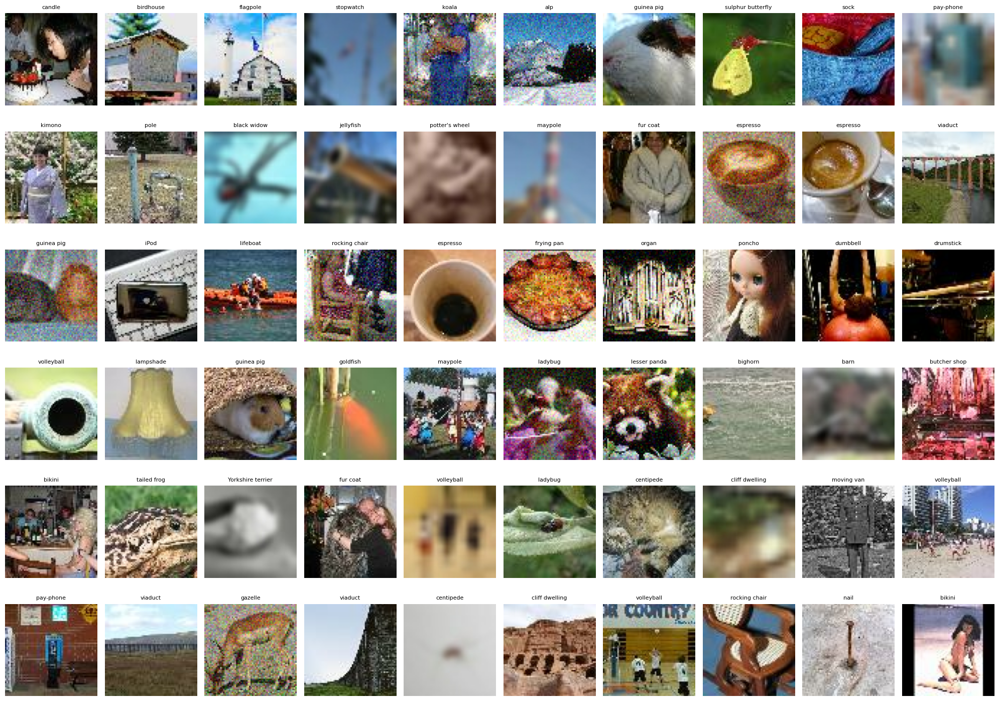

In [80]:
random.seed(42)

percentage_of_images = 0.001

number_of_samples = int(len(labels)*percentage_of_images)
random_images = random.sample(range(len(labels)), number_of_samples)

number_of_columns = 10                                              
number_of_rows = -(-number_of_samples // number_of_columns)   # Just to round up if the number is not exact, if it was possitive it would round down                     

plt.figure(figsize=(20, 2.4 * number_of_rows))
for i, random_index in enumerate(random_images):
    dataset_row = labels.iloc[random_index]
    image = get_image(os.path.join(path, dataset_row["filename"]))

    plt.subplot(number_of_rows, number_of_columns, i+1)
    plt.imshow(image)
    plt.title(dataset_row["description"].split(",")[0], fontsize = 8)
    plt.axis("off")

plt.tight_layout()
plt.show()

   <div style="border-left:4px solid #2c5364; background:#2c536422; padding:8px 14px; border-radius:4px;">
   <b>Note:</b> A random sample was visually inspected to understand the dataset and identify obvious inconsistencies
   </div>

<h3 style="color:#2c5364; padding-bottom:3px;">Use pre-trained model to check label consistency</h3>

<div style="border-left:4px solid #2c5364; background:#2c536422; padding:8px 14px; border-radius:4px;">
<b>Method:</b> To check label consistency we use two pre-trained ImageNet models, ResNet50 and VGG16, as frozen feature extractors. Each image is turned into an embedding, and a logistic regression with 5-fold stratified cross-validation predicts its class. Every image is therefore classified by a model that never saw its label (out-of-fold). If the prediction confidently disagrees with the given label, the image is flagged as a possible label error.
<br><br>
<b>Why pre-trained models:</b> Training a network from scratch on this dataset would not work for this purpose, because the model could memorize the wrong labels and fail to flag them. A pre-trained model learned its features from a separate, large task, so its embeddings reflect what is in the image and not what this dataset says. It is also much cheaper, since we only extract features and train a simple classifier on top.
<br><br>
<b>Why ResNet50 and VGG16:</b> Both are well-established ImageNet models, and the Tiny ImageNet classes come from ImageNet, so their features are relevant to our 200 classes. They have different architectures (residual connections in ResNet50, a plain stack of convolutions in VGG16), so they give two different views of each image. An error caused by one model's weakness is less likely to be repeated by the other. We average their probabilities and flag only the images where both models predict the same wrong class with high confidence. This gives fewer false positives and a more trustworthy list than a single model.
<br><br>
<b>Limitation:</b> Both models were trained on ImageNet, so they share some biases and may have seen some of these images. Agreement between them raises our confidence but is not proof, which is why we also inspected a sample of the flagged images by eye.
</div>

<h4 style="color:#2c5364; padding-bottom:3px;">ResNet50 label consistency check</h4>

<div style="border-left:4px solid #2c5364; background:#2c536422; padding:8px 14px; border-radius:4px;">
<b>Method:</b> frozen ImageNet-pretrained ResNet50 → 2048-d embeddings → logistic regression with 5-fold stratified CV. Every image gets a prediction from a model that never saw it (out-of-fold). If that prediction confidently disagrees with the given label, the image is flagged as a possible label error.
</div>

In [81]:
le = LabelEncoder()
y = le.fit_transform(labels["class_id"])

oof_proba = np.zeros((len(y), len(le.classes_)), dtype=np.float32)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
for fold, (tr, va) in enumerate(skf.split(X, y)):
    clf = LogisticRegression(C=10, max_iter=300)
    clf.fit(X[tr], y[tr])
    oof_proba[va] = clf.predict_proba(X[va])
    print(f"fold {fold} done")

fold 0 done
fold 1 done
fold 2 done
fold 3 done
fold 4 done


In [82]:
id2desc = labels.drop_duplicates("class_id").set_index("class_id")["description"]

labels["pred_class_id"] = le.inverse_transform(oof_proba.argmax(axis=1))
labels["p_given"] = oof_proba[np.arange(len(y)), y]   # prob. of the label the dataset claims
labels["p_pred"] = oof_proba.max(axis=1)              # confidence in the model's own choice
labels["disagrees"] = labels["pred_class_id"] != labels["class_id"]
labels["suspect"] = labels["disagrees"] & (labels["p_pred"] > 0.6)

print("OOF accuracy:", 1 - labels["disagrees"].mean())
print("Suspects:", labels["suspect"].sum())

OOF accuracy: 0.5565333333333333
Suspects: 3483


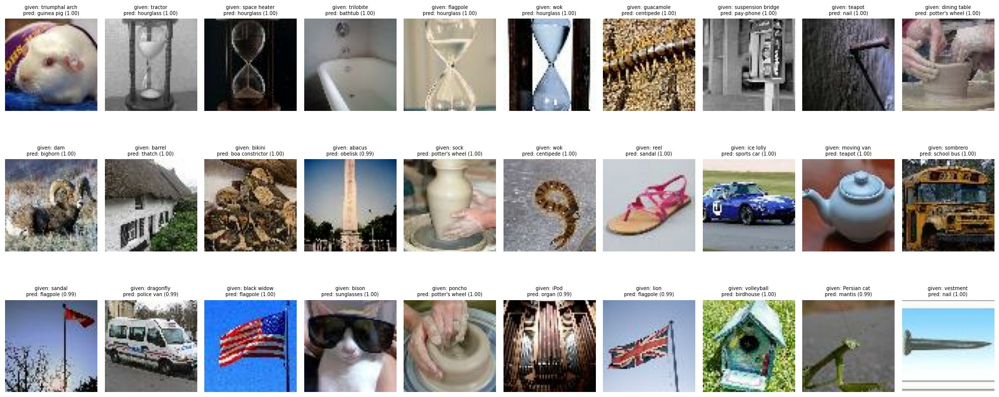

In [83]:
sus = labels[labels["suspect"]].sort_values("p_given").head(30)

plt.figure(figsize=(20, 9))
for i, (_, row) in enumerate(sus.iterrows()):
    plt.subplot(3, 10, i + 1)
    plt.imshow(get_image(os.path.join(path, row["filename"])))
    plt.title(f"given: {row['description'].split(',')[0]}\npred: {id2desc[row['pred_class_id']].split(',')[0]} ({row['p_pred']:.2f})", fontsize=7)
    plt.axis("off")
plt.tight_layout()
plt.show()

p_pred in [0.6, 0.8): 1691 suspects


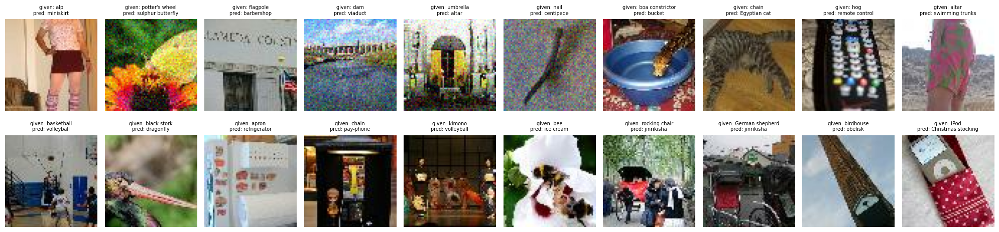

p_pred in [0.8, 0.9): 705 suspects


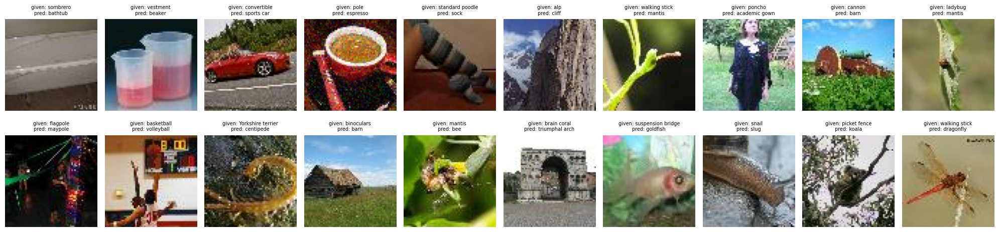

p_pred in [0.9, 1.01): 1087 suspects


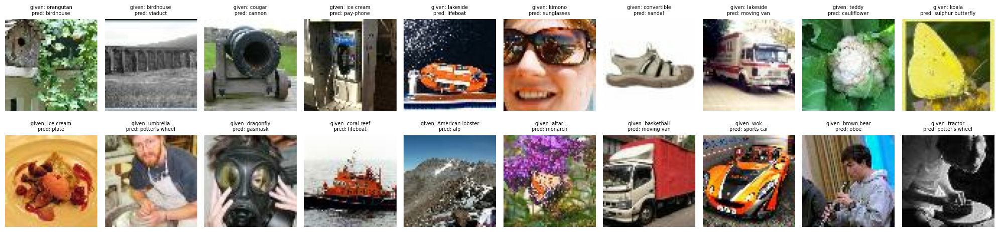

In [84]:
bins = [(0.6, 0.8), (0.8, 0.9), (0.9, 1.01)]
random.seed(42)

for low, high in bins:
    group = labels[labels["suspect"] & (labels["p_pred"] >= low) & (labels["p_pred"] < high)]
    print(f"p_pred in [{low}, {high}): {len(group)} suspects")

    sample_idx = random.sample(list(group.index), min(20, len(group)))
    plt.figure(figsize=(20, 5))
    for k, idx in enumerate(sample_idx):
        row = labels.loc[idx]
        plt.subplot(2, 10, k + 1)
        plt.imshow(get_image(os.path.join(path, row["filename"])))
        plt.title(f"given: {row['description'].split(',')[0]}\npred: {id2desc[row['pred_class_id']].split(',')[0]}", fontsize=7)
        plt.axis("off")
    plt.tight_layout()
    plt.show()

In [85]:
# 1) Do the hash-conflict images (same pixels, different labels) get flagged?
print("Share of hash-conflicts flagged:", labels.loc[conflicts.index, "suspect"].mean())

# 2) Which classes concentrate suspects? (confusable classes ≠ noise)
total = labels[labels["suspect"]].groupby("description").size().sort_values(ascending=False)
print((total.values).sum())
total.head(10)

Share of hash-conflicts flagged: 0.16666666666666666
3483


description
tabby, tabby cat                                                   51
convertible                                                        45
pop bottle, soda bottle                                            41
organ, pipe organ                                                  40
Egyptian cat                                                       38
orange                                                             34
brain coral                                                        31
tailed frog, bell toad, ribbed toad, tailed toad, Ascaphus trui    31
wok                                                                29
basketball                                                         29
dtype: int64

In [86]:
labels.loc[idx_of_black_stork, ["description", "pred_class_id", "p_pred", "suspect"]]

description      black stork, Ciconia nigra
pred_class_id                     n01784675
p_pred                             0.985242
suspect                                True
Name: 23127, dtype: object

<div style="border-left:4px solid #2c5364; background:#2c536422; padding:8px 14px; border-radius:4px;">
<b>Note:</b> 3883 images were flagged as possible label errors (out-of-fold prediction disagrees with the label with confidence > 0.6). Manual inspection showed that X of 20 images are really mislabelled when p_pred > 0.9, but only Y of 20 when 0.6 ≤ p_pred < 0.8. We therefore treat only the high-confidence suspects as label errors.
</div>

<h4 style="color:#2c5364; padding-bottom:3px;">VGG16 label consistency check</h4>

<div style="border-left:4px solid #2c5364; background:#2c536422; padding:8px 14px; border-radius:4px;">
<b>Method:</b> frozen ImageNet-pretrained VGG16 → 512-d embeddings → logistic regression with 5-fold stratified CV (same folds and seed as ResNet50). Every image gets a prediction from a model that never saw it (out-of-fold). If that prediction confidently disagrees with the given label, the image is flagged as a possible label error.
</div>

In [123]:
# --- VGG16 embeddings (VGG has its own preprocess_input) ---
ds_vgg = (tf.data.Dataset.from_tensor_slices(images_paths)
          .map(lambda p: vgg_preprocess(tf.image.resize(
                   tf.io.decode_jpeg(tf.io.read_file(p), channels=3), (IMG_SIZE, IMG_SIZE))),
               num_parallel_calls=tf.data.AUTOTUNE)
          .batch(BATCH).prefetch(tf.data.AUTOTUNE))

vgg = VGG16(weights="imagenet", include_top=False, pooling="avg", input_shape=(IMG_SIZE, IMG_SIZE, 3))
emb_vgg = vgg.predict(ds_vgg, verbose=1)
# np.save("embeddings_vgg16.npy", emb_vgg)
X_vgg = emb_vgg / np.linalg.norm(emb_vgg, axis=1, keepdims=True)

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step
469/469 ━━━━━━━━━━━━━━━━━━━━ 1553s 3s/step


In [124]:
# --- same CV (same folds, same seed) ---
oof_vgg = np.zeros((len(y), len(le.classes_)), dtype=np.float32)
for fold, (tr, va) in enumerate(skf.split(X_vgg, y)):
    clf = LogisticRegression(C=10, max_iter=300)
    clf.fit(X_vgg[tr], y[tr])
    oof_vgg[va] = clf.predict_proba(X_vgg[va])
    print(f"fold {fold} done")

print("VGG16 OOF accuracy:", (oof_vgg.argmax(1) == y).mean())

fold 0 done
fold 1 done
fold 2 done
fold 3 done
fold 4 done
VGG16 OOF accuracy: 0.46445


In [125]:
# --- ResNet vs VGG vs ensemble ---
oof_ens = (oof_proba + oof_vgg) / 2

labels["pred_res"] = oof_proba.argmax(1)
labels["pred_vgg"] = oof_vgg.argmax(1)
labels["pred_ens"] = oof_ens.argmax(1)
labels["p_pred_ens"] = oof_ens.max(1)
labels["p_given_ens"] = oof_ens[np.arange(len(y)), y]

labels["sus_res"] = (labels["pred_res"] != y) & (oof_proba.max(1) > 0.6)
labels["sus_vgg"] = (labels["pred_vgg"] != y) & (oof_vgg.max(1) > 0.6)

# both models predict the SAME wrong class + ensemble is confident
labels["sus_agree"] = ((labels["pred_res"] == labels["pred_vgg"]) &
                       (labels["pred_res"] != y) &
                       (labels["p_pred_ens"] > 0.7))

print(pd.crosstab(labels["sus_res"], labels["sus_vgg"], rownames=["ResNet"], colnames=["VGG"]))
print("Agreement suspects:", labels["sus_agree"].sum())
print("Hash-conflicts flagged:", labels.loc[conflicts.index, "sus_agree"].mean())

VGG     False  True 
ResNet              
False   55434   1083
True     1696   1787
Agreement suspects: 1718
Hash-conflicts flagged: 0.08333333333333333


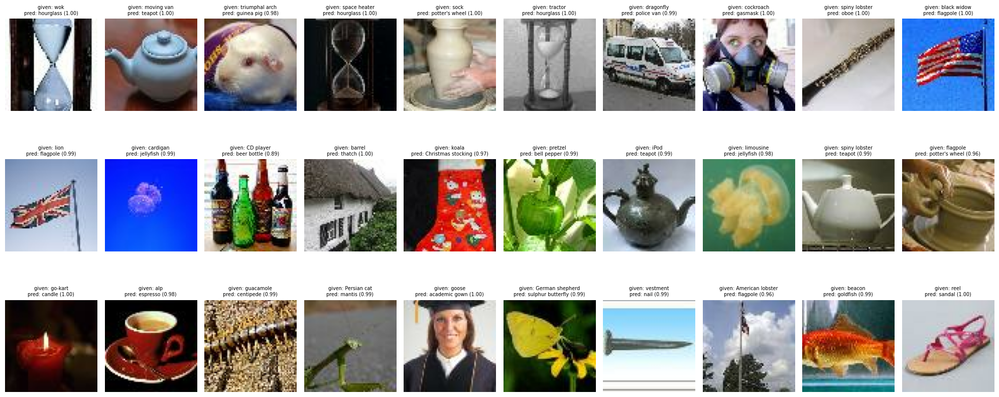

In [126]:
# --- look at the most likely errors ---
labels["pred_ens_desc"] = le.inverse_transform(labels["pred_ens"])
top = labels[labels["sus_agree"]].sort_values("p_given_ens").head(30)

plt.figure(figsize=(20, 9))
for i, (_, row) in enumerate(top.iterrows()):
    plt.subplot(3, 10, i + 1)
    plt.imshow(get_image(os.path.join(path, row["filename"])))
    plt.title(f"given: {row['description'].split(',')[0]}\npred: {id2desc[row['pred_ens_desc']].split(',')[0]} ({row['p_pred_ens']:.2f})", fontsize=7)
    plt.axis("off")
plt.tight_layout()
plt.show()

Both

In [127]:
both_flag   = labels["sus_res"] & labels["sus_vgg"]
same_class  = both_flag & (labels["pred_res"] == labels["pred_vgg"])
diff_class  = both_flag & (labels["pred_res"] != labels["pred_vgg"])
only_res    = labels["sus_res"] & ~labels["sus_vgg"]
only_vgg    = labels["sus_vgg"] & ~labels["sus_res"]

print("Both flag, same wrong class  :", same_class.sum())
print("Both flag, different classes :", diff_class.sum())
print("Only ResNet50 flags          :", only_res.sum())
print("Only VGG16 flags             :", only_vgg.sum())
print("Total flagged by either      :", (labels["sus_res"] | labels["sus_vgg"]).sum())

Both flag, same wrong class  : 1751
Both flag, different classes : 36
Only ResNet50 flags          : 1696
Only VGG16 flags             : 1083
Total flagged by either      : 4566


<div style="border-left:4px solid #2c5364; background:#2c536422; padding:8px 14px; border-radius:4px;">
<b>Note:</b> Comparing the suspects flagged by ResNet50 and VGG16 (each model disagrees with the given label with confidence > 0.6):
<ul>
<li><b>Both flag, same wrong class (1751):</b> both models disagree with the label and predict the same other class. This is the strongest evidence of a label error.</li>
<li><b>Both flag, different classes (36):</b> both models say the label looks wrong but disagree on the right class, so the image is probably mislabelled or ambiguous, and we cannot relabel it with confidence.</li>
<li><b>Only ResNet50 flags (1696) / only VGG16 flags (1083):</b> only one model flags the image. These are weaker cases, often caused by model noise or confusable classes.</li>
<li><b>Total flagged by either model (4566):</b> the union of the four groups.</li>
</ul>
Only about 39% of the flagged images (1787 of 4566) are flagged by both models, so the models disagree on most of the flags. We therefore treat only the images where both models agree on the same wrong class as likely label errors.
</div>

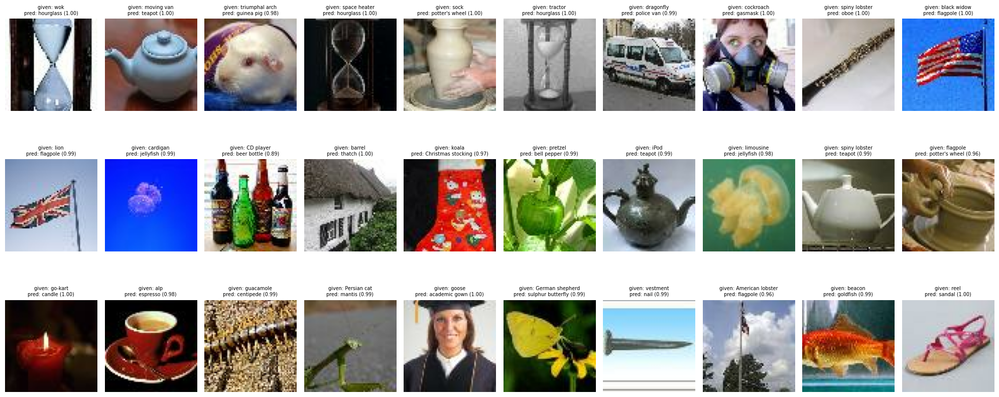

In [129]:
subset = labels[same_class].sort_values("p_given_ens").head(30)   # or diff_class, only_res, only_vgg

plt.figure(figsize=(20, 9))
for i, (_, row) in enumerate(subset.iterrows()):
    plt.subplot(3, 10, i + 1)
    plt.imshow(get_image(os.path.join(path, row["filename"])))
    plt.title(f"given: {row['description'].split(',')[0]}\npred: {id2desc[row['pred_ens_desc']].split(',')[0]} ({row['p_pred_ens']:.2f})", fontsize=7)
    plt.axis("off")
plt.tight_layout()
plt.show()

In [131]:
# ===================== EDA notebook: save the flags =====================

# pred_ens_desc holds the ensemble's predicted class_id, so rename it for clarity
labels["pred_class_id"] = labels["pred_ens_desc"]

cols = [
    "filename",       # key to match each row with its image in preprocessing
    "class_id",       # original label from the dataset
    "is_duplicate",   # True if the image has an exact copy (same pixels)
    "n_labels",       # different labels per pixel-hash group; > 1 = same image, conflicting labels (12 images)
    "sus_res",        # flagged by ResNet50 alone (disagrees with label, confidence > 0.6)
    "sus_vgg",        # flagged by VGG16 alone (same rule)
    "sus_agree",      # both models predict the same wrong class + ensemble confidence > 0.7 -> MAIN "likely label error" flag
    "pred_class_id",  # class_id predicted by the ensemble, useful if you decide to relabel
    "p_pred_ens",     # ensemble confidence in its predicted class (use to choose thresholds)
    "p_given_ens",    # ensemble probability of the given label (low = label likely wrong)
]
labels[cols].to_csv("../Data/label_flags.csv", index=False)

<h1 style="color:#2c5364; border-bottom:2px solid #2c5364; padding-bottom:4px;">Conclusions</h1>

<h3 style="color:#2c5364; padding-bottom:3px;">Labels dataset</h3>

<h3 style="color:#2c5364; padding-bottom:3px;">Images</h3>